In [9]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
import matplotlib.pyplot as plt
import nltk

from nltk.corpus import stopwords


import string
from nltk.stem.porter import PorterStemmer
ps = PorterStemmer()

In [10]:

from wordcloud import WordCloud


In [11]:
import kagglehub
path = kagglehub.dataset_download("uciml/sms-spam-collection-dataset")

Using Colab cache for faster access to the 'sms-spam-collection-dataset' dataset.


In [12]:
df = pd.read_csv(
    path + "/spam.csv",
    encoding="latin1",
    usecols=[0, 1],
    names=["result", "text"],
    header=0
)

df.head()

,result,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   result  5572 non-null   object
 1   text    5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [14]:
label=LabelEncoder()
df['result']=label.fit_transform(df['result'])

In [15]:
df.head()

,result,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [16]:
df.duplicated().sum()

np.int64(403)

In [17]:
df.drop_duplicates(inplace=True)

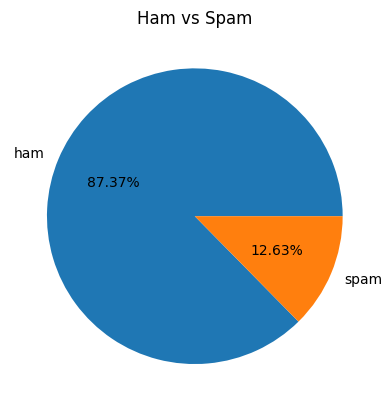

In [18]:
# Distribution of data
plt.pie(df['result'].value_counts(),labels=['ham','spam'],autopct='%.2f%%')
plt.ylabel("")
plt.title("Ham vs Spam")
plt.show()

In [20]:
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [22]:
# Creating the new_features
df['char_no'] = df['text'].apply(lambda x:len(x))
df['words_no'] = df['text'].apply(lambda x : len(nltk.word_tokenize(x)))
df['sent_no'] = df['text'].apply(lambda x : len(nltk.sent_tokenize(x)))

In [23]:
df

,result,text,char_no,words_no,sent_no
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1
...,...,...,...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...,161,35,4
5568,0,Will Ì_ b going to esplanade fr home?,37,9,1
5569,0,"Pity, * was in mood for that. So...any other s...",57,15,2
5570,0,The guy did some bitching but I acted like i'd...,125,27,1


In [24]:
df[['char_no','words_no','sent_no']].describe()

,char_no,words_no,sent_no
count,5169.000000,5169.000000,5169.000000
mean,78.977945,18.455794,1.965564
std,58.236293,13.324758,1.448541
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,60.000000,15.000000,1.000000
75%,117.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


In [25]:
# For ham SMS
df[df['result'] == 0][['char_no','words_no','sent_no']].describe()

,char_no,words_no,sent_no
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.123782,1.820195
std,56.358207,13.493970,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [26]:
# For spam SMS
df[df['result'] == 1][['char_no','words_no','sent_no']].describe()

,char_no,words_no,sent_no
count,653.000000,653.000000,653.000000
mean,137.891271,27.667688,2.970904
std,30.137753,7.008418,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


<Axes: xlabel='char_no', ylabel='Count'>

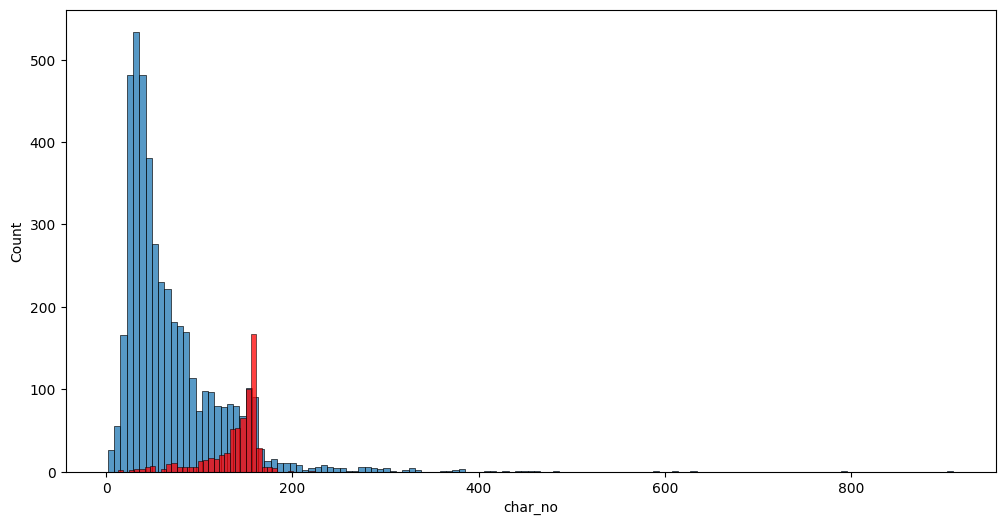

In [27]:
# Histogram for char_no for ham & spam
plt.figure(figsize=(12,6))
sns.histplot(df[df['result'] == 0 ]['char_no'])
sns.histplot(df[df['result'] == 1 ]['char_no'],color='red')

<Axes: xlabel='words_no', ylabel='Count'>

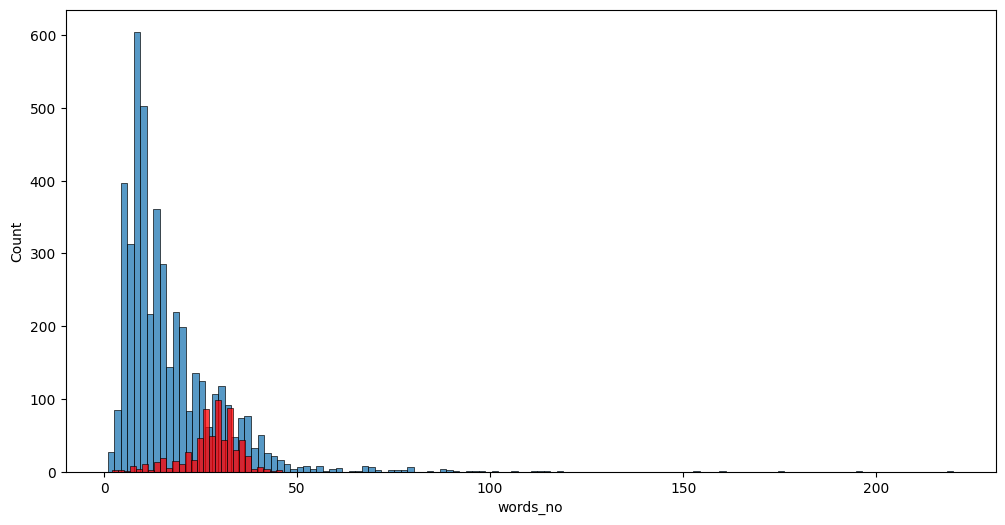

In [28]:
# Histogram for words_no for ham & spam
plt.figure(figsize=(12,6))
sns.histplot(df[df['result'] == 0 ]['words_no'])
sns.histplot(df[df['result'] == 1 ]['words_no'],color='red')

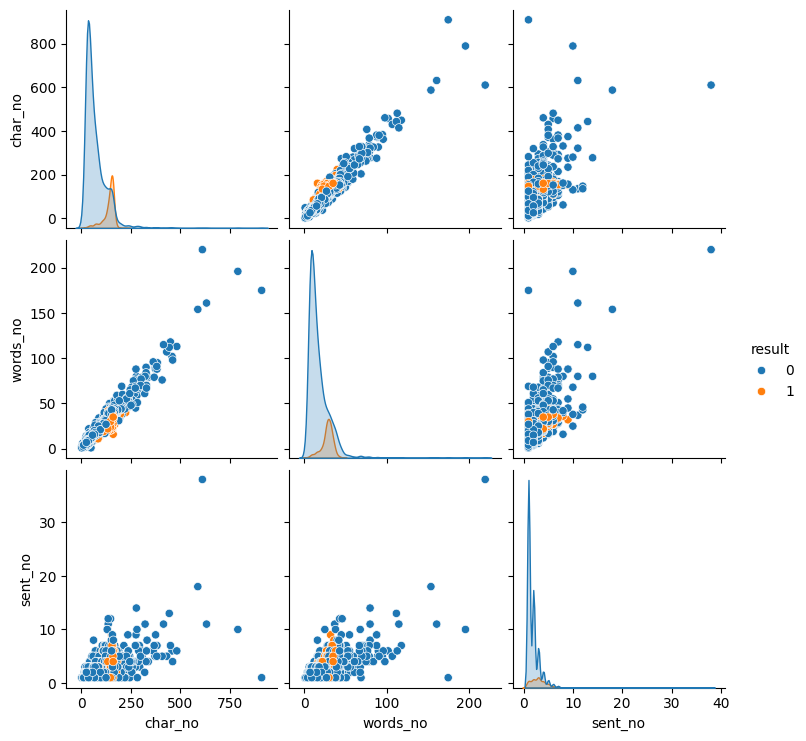

In [29]:
# Relation between the 3 features created
sns.pairplot(df,hue='result')

<Axes: >

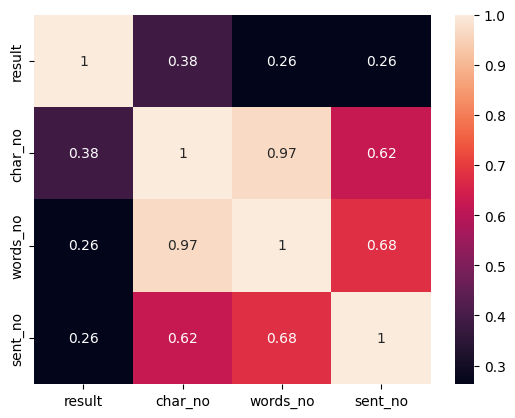

In [30]:
sns.heatmap(df[['result','char_no','words_no','sent_no']].corr(),annot=True)

In [31]:
# Data Preprocessing
def preprocess(text):
    text = text.lower()
    text = nltk.word_tokenize(text)

    y=[]
    for i in text:
        if i.isalnum():
            y.append(i)

    text = y[:]
    y.clear()

    for i in text:
        if i  not in stopwords.words('english') and i not in string.punctuation:
            y.append(i)
    text = y[:]
    y.clear()

    for i in text:
        y.append(ps.stem(i))

    return " ".join(y)


In [32]:
df['pre_processed_text'] = df['text'].apply(preprocess)

In [33]:
df

,result,text,char_no,words_no,sent_no,pre_processed_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though
...,...,...,...,...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...,161,35,4,2nd time tri 2 contact u pound prize 2 claim e...
5568,0,Will Ì_ b going to esplanade fr home?,37,9,1,b go esplanad fr home
5569,0,"Pity, * was in mood for that. So...any other s...",57,15,2,piti mood suggest
5570,0,The guy did some bitching but I acted like i'd...,125,27,1,guy bitch act like interest buy someth els nex...


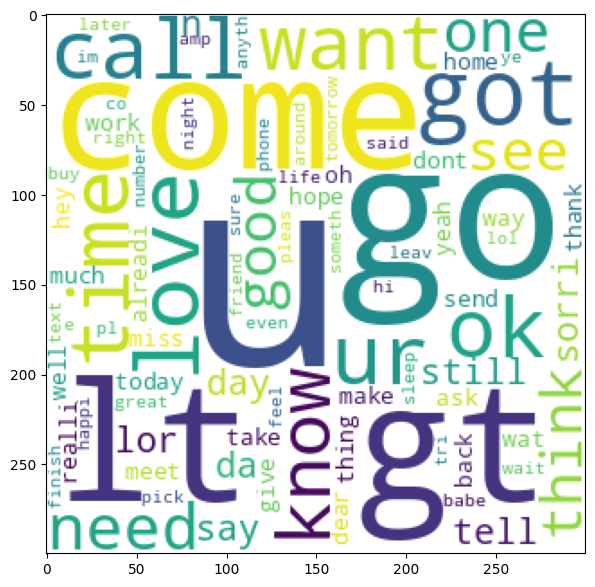

In [34]:
# Wordcloud from ham SMS
wc = WordCloud(width=300 , height=300 , min_font_size = 10 , background_color='white' )
wc_ham = wc.generate(df[df['result'] == 0]['pre_processed_text'].str.cat(sep=" "))
plt.figure(figsize=(12,7))
plt.imshow(wc_ham)

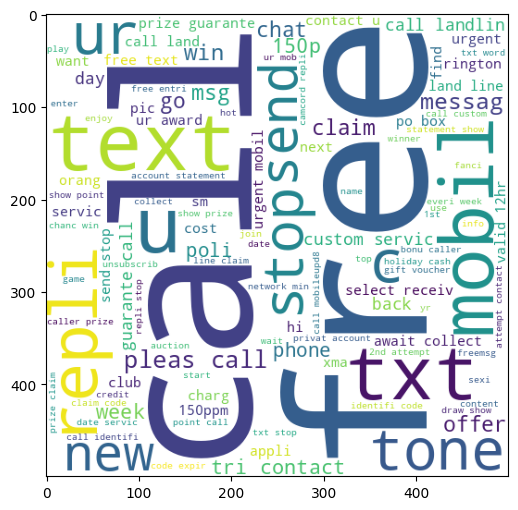

In [35]:
# Wordcloud from spam SMS
wc = WordCloud(width=500 , height=500 , min_font_size = 10 , background_color='white' )
wc_spam = wc.generate(df[df['result'] == 1]['pre_processed_text'].str.cat(sep=" "))
plt.figure(figsize=(12,6))
plt.imshow(wc_spam)

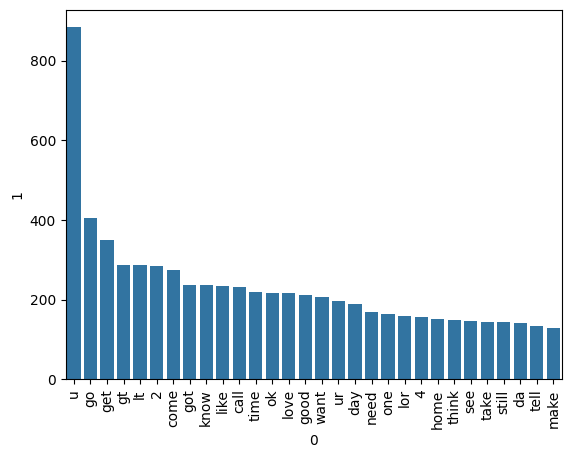

In [36]:
# Getting top 30 words and its repetation in ham
ham_corpus = []
for msg in df[df['result'] == 0 ]['pre_processed_text'] :
    for word in msg.split():
        ham_corpus.append(word)
from collections import Counter
sns.barplot(x=pd.DataFrame(Counter(ham_corpus).most_common(30))[0],
            y=pd.DataFrame(Counter(ham_corpus).most_common(30))[1])
plt.xticks(rotation='vertical')
plt.show()

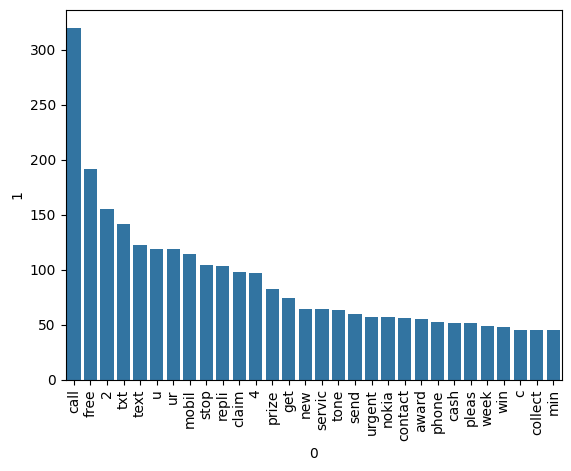

In [37]:
# Getting top 30 words and its repetation in spam
spam_corpus = []
for msg in df[df['result'] == 1 ]['pre_processed_text'] :
    for word in msg.split():
        spam_corpus.append(word)
from collections import Counter
sns.barplot(x=pd.DataFrame(Counter(spam_corpus).most_common(30))[0],
            y=pd.DataFrame(Counter(spam_corpus).most_common(30))[1])
plt.xticks(rotation='vertical')
plt.show()

In [47]:
X = df['pre_processed_text']
y = df['result'].values

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=64
)

tfidf = TfidfVectorizer()

X_train = tfidf.fit_transform(X_train)
X_test = tfidf.transform(X_test)

In [48]:
# from sklearn.preprocessing import MinMaxScaler

# scaler = MinMaxScaler()

# X_train = scaler.fit_transform(X_train.toarray())
# X_test = scaler.transform(X_test.toarray())

In [49]:
# Alogorithms
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier

In [50]:
svc = SVC(kernel='sigmoid', gamma=1.0)
knc = KNeighborsClassifier()
mnb = MultinomialNB()
dtc = DecisionTreeClassifier(max_depth=5)
lrc = LogisticRegression(solver='liblinear', penalty='l1')
rfc = RandomForestClassifier(n_estimators=50, random_state=2)
abc = AdaBoostClassifier(n_estimators=50, random_state=2)
bc = BaggingClassifier(n_estimators=50, random_state=2)
etc = ExtraTreesClassifier(n_estimators=50, random_state=2)
gbdt = GradientBoostingClassifier(n_estimators=50,random_state=2)
xgb = XGBClassifier(n_estimators=50,random_state=2)
from sklearn.metrics import accuracy_score, precision_score

In [51]:
clfs = {
'SVC' : svc,
'KN' : knc,
'NB': mnb,
'DT': dtc,
'LR': lrc,
'RF': rfc,
'AdaBoost': abc,
'BgC': bc,
'ETC': etc,
'GBDT':gbdt,
'xgb':xgb

}

In [52]:
def model_train(clf,X_train,y_train,X_test,y_test):
    clf.fit(X_train,y_train)
    y_predict = clf.predict(X_test)
    accuracy = accuracy_score(y_test,y_predict)
    precision = precision_score(y_test,y_predict)
    return accuracy,precision

In [53]:
accuracy_scores = []
precision_scores = []
for name,clf in clfs.items():
    current_accuracy, current_precision = model_train(clf, X_train, y_train, X_test, y_test)

    print("For ",name)
    print("Accuracy - ", current_accuracy)
    print("Precision - ",current_precision)
    accuracy_scores.append(current_accuracy)
    precision_scores.append(current_precision)

For  SVC
Accuracy -  0.9825918762088974
Precision -  0.9663865546218487
For  KN
Accuracy -  0.9119922630560928
Precision -  1.0
For  NB
Accuracy -  0.9700193423597679
Precision -  1.0
For  DT
Accuracy -  0.9323017408123792
Precision -  0.8241758241758241
For  LR
Accuracy -  0.9555125725338491
Precision -  0.8952380952380953
For  RF
Accuracy -  0.9680851063829787
Precision -  1.0
For  AdaBoost
Accuracy -  0.9245647969052224
Precision -  0.8227848101265823
For  BgC
Accuracy -  0.9593810444874274
Precision -  0.9142857142857143
For  ETC
Accuracy -  0.9758220502901354
Precision -  0.9905660377358491
For  GBDT
Accuracy -  0.9526112185686654
Precision -  0.9347826086956522
For  xgb
Accuracy -  0.9642166344294004
Precision -  0.9423076923076923


In [54]:
results = pd.DataFrame({
    'Classifier': list(clfs.keys()),
    'Accuracy': accuracy_scores,
    'Precision': precision_scores
})

results.sort_values('Precision', ascending=False)

,Classifier,Accuracy,Precision
1,KN,0.911992,1.000000
2,NB,0.970019,1.000000
5,RF,0.968085,1.000000
8,ETC,0.975822,0.990566
0,SVC,0.982592,0.966387
10,xgb,0.964217,0.942308
9,GBDT,0.952611,0.934783
7,BgC,0.959381,0.914286
4,LR,0.955513,0.895238
3,DT,0.932302,0.824176


In [55]:
import pickle
pickle.dump(tfidf,open('vectorizer.pkl','wb'))
pickle.dump(mnb,open('model.pkl','wb'))

In [56]:
import os
print(os.getcwd())
print(os.listdir())

/content
['.config', 'model.pkl', 'vectorizer.pkl', 'sample_data']
